# MS6 — Comparaison : clustering SANS vs AVEC contrainte de rayon · Notebook 07

**Question.** Que change le nouveau paramètre **`rayon_max`** (distance routière max élève→médoïde) par rapport
à l'approche actuelle (capacité seule) ?

- **Approche A — SANS contrainte** (actuelle) : k-médoïdes capacitaire, on minimise la dispersion (objectif mou).
- **Approche B — AVEC contrainte** : on **garantit** `dist(élève, médoïde) ≤ R` (SLA) ; les élèves trop loin
  deviennent **dispersés** (groupe 999, ramassage individuel).

Distances = **routières OSRM réelles**. On compare métriques + cartes, puis on donne le verdict honnête.

**Étape 0 — Environnement.**

In [1]:
import os, sys, warnings, asyncio
warnings.filterwarnings("ignore")
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
os.makedirs("notebooks/figures", exist_ok=True); FIG = "notebooks/figures"
import config
from features import extraire_coords, projeter_metres, matrice_euclidienne
from osrm_client import matrice_routiere
from clustering import _compute_production
print("cwd:", os.getcwd())

cwd: C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms6-clustering


**Étape 1 — Données + matrice routière OSRM (live, sinon cachée).**

In [2]:
df = pd.read_csv("data/eleves_meknes.csv")
eleves = [{"id": int(r.id), "latitude": float(r.latitude), "longitude": float(r.longitude)} for r in df.itertuples()]
ids, latlon = extraire_coords(eleves); XY, proj = projeter_metres(latlon)
try:
    D = await matrice_routiere(latlon); src = "routière OSRM (live)"
except Exception as e:
    try:
        D = np.load("data/osrm_dist_m.npy"); src = "routière OSRM (cachée)"
    except Exception:
        D = matrice_euclidienne(XY); src = "euclidienne (repli)"
print(len(ids), "élèves | distances :", src)
CAP = 50; R_AVEC = 2000     # rayon routier retenu pour l'approche B (m)
KM, MS, IT = config.settings.k_margin, config.settings.min_silhouette, config.settings.kmedoids_iters

300 élèves | distances : routière OSRM (live)


**Étape 2 — Lancer les 2 approches** (même matrice, même capacité).

In [3]:
A = _compute_production(ids, XY, D, CAP, KM, MS, IT, rayon_max=0)       # SANS
B = _compute_production(ids, XY, D, CAP, KM, MS, IT, rayon_max=R_AVEC)  # AVEC
def ligne(res, nom):
    m = res["metrics"]
    return {"approche": nom, "k_bus": res["k"], "compacite_max_m": m.get("compacite_max_m"),
            "compacite_med_m": m.get("compacite_med_m"), "silhouette": m.get("silhouette"),
            "taille_max": m.get("taille_max"), "non_affectes": res["n_non_affectes"]}
comp = pd.DataFrame([ligne(A, "SANS (capacité seule)"), ligne(B, f"AVEC (rayon ≤ {R_AVEC} m)")])
comp

[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


,approche,k_bus,compacite_max_m,compacite_med_m,silhouette,taille_max,non_affectes
0,SANS (capacité seule),8,2804.1,727.3,0.4056,47,0
1,AVEC (rayon ≤ 2000 m),6,1983.1,729.2,0.4766,50,42


**Étape 3 — Comparaison visuelle des métriques.** La contrainte réduit la **compacité max** (garantie) et améliore la **silhouette**, au prix des **dispersés**.

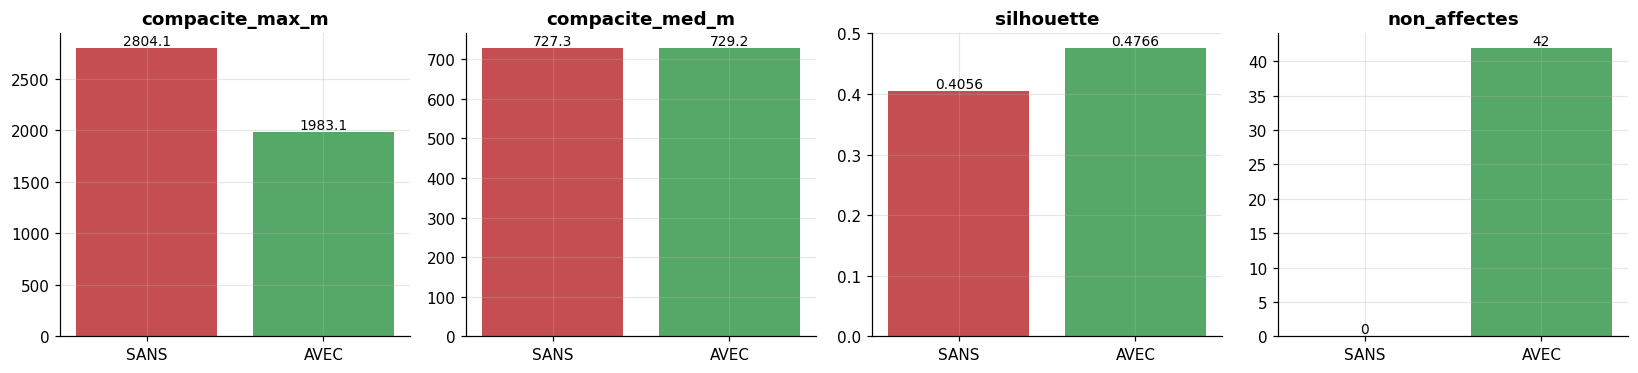

In [4]:
labels = ["compacite_max_m", "compacite_med_m", "silhouette", "non_affectes"]
va = [A["metrics"].get("compacite_max_m"), A["metrics"].get("compacite_med_m"), A["metrics"].get("silhouette"), A["n_non_affectes"]]
vb = [B["metrics"].get("compacite_max_m"), B["metrics"].get("compacite_med_m"), B["metrics"].get("silhouette"), B["n_non_affectes"]]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for i, lab in enumerate(labels):
    ax[i].bar(["SANS", "AVEC"], [va[i], vb[i]], color=["#C44E52", "#55A868"])
    ax[i].set_title(lab)
    for j, val in enumerate([va[i], vb[i]]): ax[i].text(j, val, f"{val}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/07_metriques_sans_vs_avec.png", bbox_inches="tight"); plt.show()

**Étape 4 — Cartes côte à côte.** À gauche SANS (des groupes peuvent s'étaler) ; à droite AVEC (groupes compacts + **dispersés en gris** hors rayon).

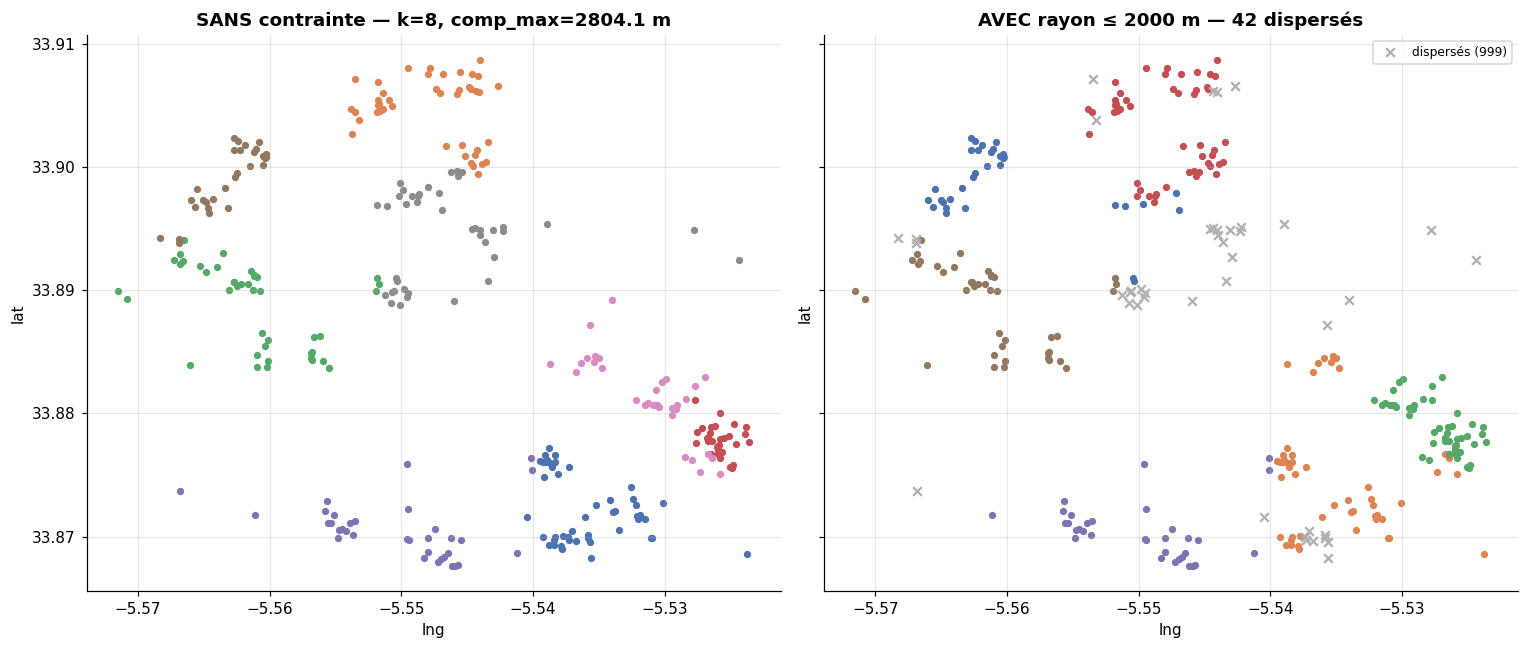

In [5]:
PAL = ["#4C72B0","#DD8452","#55A868","#C44E52","#8172B3","#937860","#DA8BC3","#8C8C8C","#CCB974","#64B5CD","#E69F00","#009E73"]
def carte(ax, res, titre):
    g = np.array([res["mapping"][int(i)] for i in ids])
    for grp in sorted(set(g)):
        m = g == grp
        if grp == 999:
            ax.scatter(latlon[m,1], latlon[m,0], c="#B0B0B0", marker="x", s=32, label="dispersés (999)")
        else:
            ax.scatter(latlon[m,1], latlon[m,0], c=PAL[(grp-1) % len(PAL)], s=14)
    ax.set_title(titre); ax.set_xlabel("lng"); ax.set_ylabel("lat")
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
carte(ax[0], A, f"SANS contrainte — k={A['k']}, comp_max={A['metrics'].get('compacite_max_m')} m")
carte(ax[1], B, f"AVEC rayon ≤ {R_AVEC} m — {B['n_non_affectes']} dispersés")
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/07_cartes_sans_vs_avec.png", bbox_inches="tight"); plt.show()

**Étape 5 — Contexte : balayage de R** (pour situer le choix). Montre l'arbitrage compacité garantie ↔ nombre de dispersés.

In [6]:
rows = []
for R in [0, 2500, 2000, 1500, 1000]:
    r = _compute_production(ids, XY, D, CAP, KM, MS, IT, rayon_max=R)
    rows.append({"rayon": "∞" if R == 0 else R, "k": r["k"],
                 "compacite_max_m": r["metrics"].get("compacite_max_m"),
                 "silhouette": r["metrics"].get("silhouette"), "non_affectes": r["n_non_affectes"]})
pd.DataFrame(rows)

[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


...

[MS6] LP capacitaire infaisable (rayon=1000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=1000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=1000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=1000) — repli glouton


,rayon,k,compacite_max_m,silhouette,non_affectes
0,∞,8,2804.1,0.4056,0
1,2500,8,2197.1,0.4189,5
2,2000,6,1983.1,0.4766,42
3,1500,6,1484.3,0.6736,95
4,1000,6,996.5,0.7246,123


### Verdict honnête
- **AVEC contrainte** : on **garantit** une compacité par élève (`compacité_max ≤ R`) → **SLA défendable** ;
  la silhouette du cœur **s'améliore**. **Coût** : des élèves hors rayon deviennent **dispersés**
  (ramassage individuel).
- **Sur distances routières**, la contrainte **mord fort** (la route ≈ 1.5-1.7× le vol d'oiseau) → il faut un
  **R réaliste** (≈ 2000-2500 m), sinon trop de dispersés.
- **Nuance** : sans contrainte, MS6 minimise déjà la dispersion → l'effet porte surtout sur les **quelques
  groupes étalés** et rend la logique **dispersés plus honnête** (on n'attache plus de force un élève trop loin).
- **Décision = métier** : l'admin choisit R selon le compromis « compacité garantie ↔ élèves en ramassage individuel ».